# 04. Clustering - Crop Recommendation

## 1. Mục tiêu

Thử nghiệm phương pháp **Unsupervised Learning (Học không giám sát)** để khám phá xem dữ liệu cây trồng có tự nhiên hình thành các nhóm tương tự nhau hay không.

Khác với bài toán phân lớp ở file `03_classification.ipynb`, các thuật toán gom cụm **không sử dụng nhãn `y` trong quá trình huấn luyện**.

Dữ liệu đầu vào là dữ liệu đã được làm sạch và chuẩn hóa bởi Thành viên 2, được lưu trong thư mục `data/processed/`.

## 2. Mô hình sử dụng

Hai thuật toán được sử dụng để thực nghiệm và so sánh:

1. **K-Means Clustering** – thuật toán gom cụm dựa trên khoảng cách đến tâm cụm.
2. **Hierarchical Clustering** – thuật toán gom cụm phân cấp.

## 3. Tiêu chí đánh giá

Các mô hình được đánh giá dựa trên:

- **Elbow Method** – sử dụng để lựa chọn số lượng cụm phù hợp cho K-Means.
- **Silhouette Score** – đánh giá mức độ tách biệt và kết dính của các cụm.
- **PCA 2D** – giảm chiều dữ liệu để trực quan hóa các cụm.
- **Đối chiếu với nhãn thực tế `y`** – chỉ thực hiện sau khi huấn luyện để xem các cụm có vô tình tương ứng với các loại cây trồng hay không.

## 4. Cài đặt và import thư viện

Các thư viện được sử dụng để đọc dữ liệu, xây dựng mô hình gom cụm, đánh giá kết quả và trực quan hóa các cụm.

> Lưu ý: Project đã có file `requirements.txt` để quản lý các thư viện cần thiết.

In [33]:
import os      # thư viện tương tác hệ điều hành
import numpy as np   # thư viện tính toán số học
import pandas as pd  # thư viện đọc và xử lý dữ liệu dạng bảng
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score  # Dùng để đánh giá mức độ khác biệt của cụm
from sklearn.decomposition import PCA    # Dùng để giảm chiều dữ liệu xuống 2D vẽ biểu đồ

print("Import thư viện thành công!")

Import thư viện thành công!


## 5. Đọc dữ liệu

Dữ liệu đã được xử lý và chuẩn hóa từ bước Preprocessing, được lưu thành các file:

- `X_train.csv`: tập đặc trưng dùng để xây dựng mô hình gom cụm.
- `X_test.csv`: tập đặc trưng dùng để kiểm tra dữ liệu.
- `y_train.csv`: nhãn thực tế, **chỉ dùng để đối chiếu sau khi gom cụm**.
- `y_test.csv`: nhãn thực tế của tập Test, không dùng trong quá trình huấn luyện gom cụm.
- `label_mapping.csv`: bảng ánh xạ giữa mã số và tên loại cây.

**Lưu ý:** Trong quá trình huấn luyện K-Means và Hierarchical Clustering, chỉ sử dụng `X_train`, tuyệt đối không đưa `y_train` vào mô hình.

In [34]:
DATA_PATH = "../data/processed/"

X_train = pd.read_csv(DATA_PATH + "X_train.csv")
X_test = pd.read_csv(DATA_PATH + "X_test.csv")

# y chỉ được đọc để đối chiếu sau khi clustering hoàn thành
y_train = pd.read_csv(DATA_PATH + "y_train.csv").squeeze()  # squeeze ép 1 bảng 2 chiều thành 1 mảng 1 chiều
y_test = pd.read_csv(DATA_PATH + "y_test.csv").squeeze()

mapping_path = DATA_PATH + "label_mapping.csv"

if os.path.exists(mapping_path):
    mapping_df = pd.read_csv(mapping_path)
    mapping_df = mapping_df.sort_values("Mã số")
    class_names = mapping_df["Tên cây"].tolist()
else:
    class_names = sorted(
        np.unique(np.concatenate([y_train.values, y_test.values]))
    )

print("Kích thước dữ liệu:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nCác đặc trưng:")
print(list(X_train.columns))

print("\nSố lớp thực tế (chỉ dùng để đối chiếu):", len(class_names))

Kích thước dữ liệu:
X_train: (1760, 7)
X_test : (440, 7)

Các đặc trưng:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Số lớp thực tế (chỉ dùng để đối chiếu): 22


## 6. Kiểm tra dữ liệu trước khi huấn luyện

Trước khi xây dựng mô hình, kiểm tra tập dữ liệu đầu vào nhằm đảm bảo `X_train` và `X_test` không chứa giá trị thiếu.

Việc kiểm tra này chỉ thực hiện trên các đặc trưng `X`, không sử dụng nhãn `y` để xây dựng mô hình.

In [35]:
missing_train = X_train.isnull().sum().sum()
missing_test = X_test.isnull().sum().sum()

print("Missing values trong X_train:", missing_train)
print("Missing values trong X_test :", missing_test)

print("Số đặc trưng:", X_train.shape[1])

if missing_train == 0 and missing_test == 0:
    print("\nDữ liệu không có missing values.")
else:
    print("\nCần kiểm tra và xử lý missing values trước khi gom cụm.")

Missing values trong X_train: 0
Missing values trong X_test : 0
Số đặc trưng: 7

Dữ liệu không có missing values.


# 7. K-Means Clustering

K-Means là thuật toán gom cụm chia dữ liệu thành `k` nhóm dựa trên khoảng cách giữa các điểm dữ liệu và tâm của từng cụm.

Trong quá trình huấn luyện, mô hình chỉ sử dụng các đặc trưng trong `X_train` và **không sử dụng `y_train`**.


## 7.1. Elbow Method

Elbow Method được sử dụng để tìm số lượng cụm `k` phù hợp cho K-Means.

Với mỗi giá trị `k`, tính **Inertia** – tổng khoảng cách bình phương từ các điểm dữ liệu đến tâm cụm gần nhất. Khi `k` tăng, Inertia giảm. Điểm "khuỷu tay" trên biểu đồ là một gợi ý để lựa chọn số cụm phù hợp.

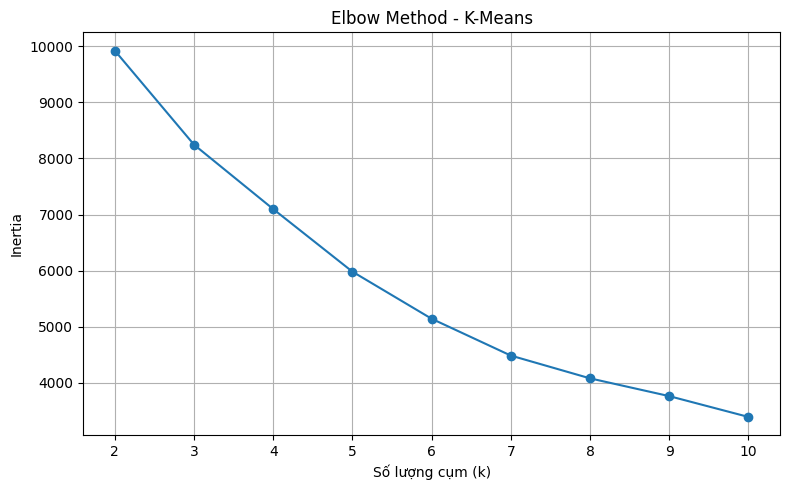

In [36]:
inertia = []   # tạo biến dùng để lưu tổng bình phương các điểm đến tâm cụm

K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_train)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

plt.xlabel("Số lượng cụm (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - K-Means")
plt.xticks(K)
plt.grid(True)

os.makedirs("../reports/figures", exist_ok=True)

plt.tight_layout()

plt.savefig(
    "../reports/figures/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 7.1.1. Lựa chọn số lượng cụm

Dựa vào biểu đồ Elbow Method ở trên, xác định vị trí đường cong bắt đầu giảm chậm rõ rệt và lựa chọn giá trị `k` phù hợp.

> **Lưu ý:** Giá trị `optimal_k` bên dưới cần được điều chỉnh theo biểu đồ thực tế sau khi chạy notebook.

Số cụm k=4 ---> Silhouette Score = 0.2446
Số cụm k=5 ---> Silhouette Score = 0.2838
Số cụm k=6 ---> Silhouette Score = 0.3085


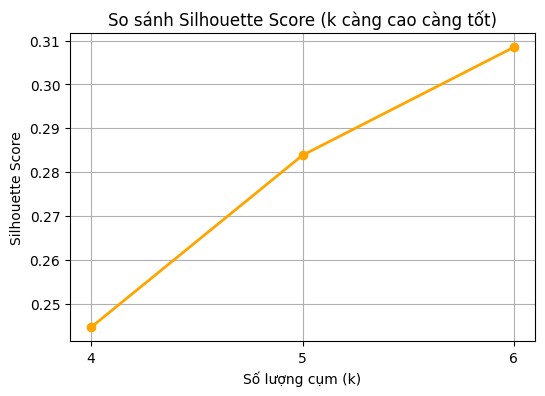

In [37]:
from sklearn.metrics import silhouette_score

k_candidates = [4, 5, 6]
sil_scores = []

for k in k_candidates:
    # Khởi tạo và chạy K-Means
    kmeans_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_test.fit_predict(X_train)
    
    # Tính Silhouette Score
    score = silhouette_score(X_train, labels)
    sil_scores.append(score)
    
    print(f"Số cụm k={k} ---> Silhouette Score = {score:.4f}")

# Vẽ biểu đồ trực quan hóa
plt.figure(figsize=(6, 4))
plt.plot(k_candidates, sil_scores, marker='o', color='orange', linewidth=2)
plt.xlabel("Số lượng cụm (k)")
plt.ylabel("Silhouette Score")
plt.title("So sánh Silhouette Score (k càng cao càng tốt)")
plt.xticks(k_candidates)
plt.grid(True)
plt.show()


In [38]:
# Thay đổi giá trị này theo điểm "khuỷu tay" quan sát được trên biểu đồ
optimal_k = 5

print("Số cụm được lựa chọn:", optimal_k)

Số cụm được lựa chọn: 5


## 7.2. Xây dựng mô hình K-Means

Sau khi xác định số lượng cụm `k`, tiến hành huấn luyện mô hình K-Means trên `X_train`.

**Không sử dụng `y_train` trong bước này.**

In [39]:
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_train)  # gán nhãn cho các điểm vào tâm cụm sau khi có tâm cụm

print("K-Means đã hoàn thành.")
print("Số cụm:", optimal_k)
print("Số lượng mẫu mỗi cụm:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means đã hoàn thành.
Số cụm: 5
Số lượng mẫu mỗi cụm:
0    427
1    177
2    489
3    160
4    507
Name: count, dtype: int64


## 7.3. Đánh giá K-Means bằng Silhouette Score

**Silhouette Score** được sử dụng để đánh giá chất lượng các cụm.

Giá trị càng gần `1` cho thấy các cụm càng tách biệt và các điểm dữ liệu trong cùng một cụm càng tương đồng. Giá trị gần `0` cho thấy các cụm có sự chồng lấn, còn giá trị âm cho thấy một số điểm có thể được phân vào cụm chưa phù hợp.

In [40]:
kmeans_score = silhouette_score(X_train, kmeans_labels)
print(f"K-Means Silhouette Score: {kmeans_score:.4f}")

K-Means Silhouette Score: 0.2838


## 7.4. Trực quan hóa K-Means bằng PCA

Do dữ liệu có nhiều đặc trưng nên sử dụng **PCA (Principal Component Analysis)** để giảm dữ liệu xuống không gian 2 chiều.

Biểu đồ Scatter Plot giúp quan sát trực quan cách K-Means phân chia dữ liệu thành các cụm.

Áp dụng PCA để giảm dữ liệu từ không gian đặc trưng ban đầu xuống 2 chiều, phục vụ việc trực quan hóa kết quả phân cụm K-Means.

In [41]:
# Giảm số chiều dữ liệu xuống 2 chiều bằng PCA để trực quan hóa
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train)  # do tập train có 7 chiều nên dùng fit_transform để nén xuống

print("X_pca shape:", X_pca.shape)

X_pca shape: (1760, 2)


C:\Users\Quang Vinh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


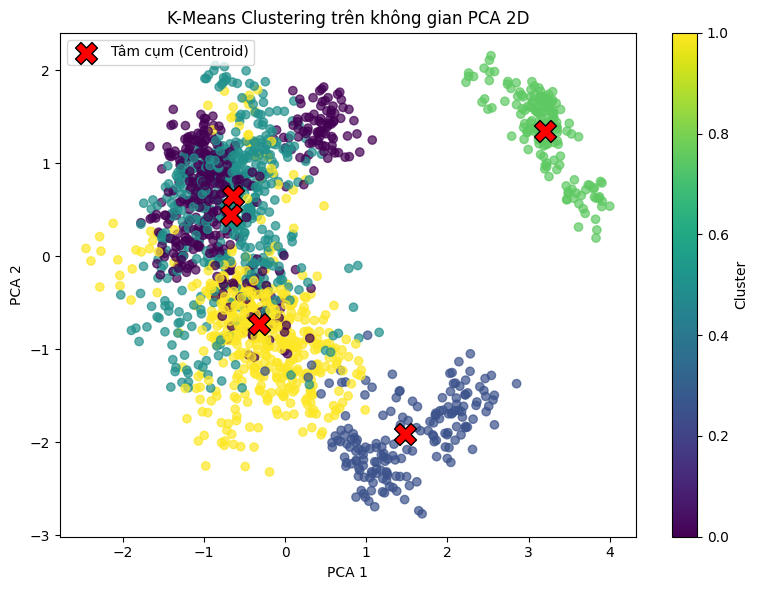

In [42]:
plt.figure(figsize=(8, 6))

# 1. Vẽ các điểm dữ liệu bình thường
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

# 2. Lấy tọa độ tâm cụm và ép xuống 2D bằng PCA
centers_pca = pca.transform(kmeans.cluster_centers_)

# 3. Vẽ các Tâm cụm (Centroids)
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    c='red',               # Cho tâm cụm màu Đỏ để nổi bật
    s=250,                 # Kích thước siêu to (250)
    marker='X',            # Dùng dấu X để phân biệt với điểm tròn
    edgecolors='black',    # Viền đen xung quanh chữ X cho sắc nét
    label='Tâm cụm (Centroid)'
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("K-Means Clustering trên không gian PCA 2D")
plt.colorbar(label="Cluster")
plt.legend() # Hiển thị chú thích (label) ở góc đồ thị

plt.tight_layout()

# Lưu lại hình (nó sẽ đè lên hình cũ)
plt.savefig(
    "../reports/figures/kmeans_clusters_2d.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Nhận xét Biểu đồ phân cụm K-Means (PCA 2D Projection)

Dựa vào biểu đồ phân tán (Scatter Plot) sau khi đã ép chiều dữ liệu từ 7D xuống 2D bằng thuật toán PCA và phân thành 5 cụm (`k=5`), ta có những nhận định sau về mức độ vón cục và tách biệt của dữ liệu:

**1. Các cụm tách biệt rất tốt (Well-separated clusters):**
- **Cụm màu xanh lá (Góc trên bên phải):** Đây là cụm có chất lượng hoàn hảo nhất. Các điểm dữ liệu bám cực kỳ sát vào tâm cụm (chữ X màu đỏ) và cách ly hoàn toàn với phần còn lại của thế giới. Điều này cho thấy nhóm cây trồng thuộc cụm này có đặc tính thổ nhưỡng/khí hậu cực kỳ đặc trưng và khác biệt hẳn so với phần đông các loại cây khác.
- **Cụm màu xanh dương sậm (Góc dưới bên phải):** Tạo thành một dải dữ liệu khá rõ ràng và tách rời. Dù không co cụm chặt bằng nhóm màu xanh lá, nhưng ranh giới của nó vẫn rất dễ nhận diện.

**2. Các cụm có sự chồng lấn (Overlapping clusters):**
- Quần thể dữ liệu lớn ở phía bên trái đồ thị bị thuật toán K-Means cắt thành 3 cụm (màu vàng, xanh lơ và tím đậm). 
- Dễ dàng nhận thấy ranh giới giữa 3 cụm này khá mờ nhạt, có rất nhiều điểm dữ liệu bị trộn lẫn (mix) vào nhau ở vùng ven của tâm cụm. Đặc biệt là tâm của cụm màu xanh lơ và cụm màu tím được đặt khá gần nhau. Sự chồng lấn này cũng chính là nguyên nhân giải thích vì sao điểm Silhouette Score tổng thể chỉ dao động ở mức quanh 0.24 - 0.26 (mức trung bình) chứ không thể vươn lên mức >0.5.

**Lưu ý quan trọng về bản chất không gian:**
Cần phải nhớ rằng biểu đồ này chỉ là **hình chiếu 2D** của một không gian dữ liệu gốc lên tới **7 chiều (7D)**. Thuật toán K-Means thực chất đã tính khoảng cách và gom cụm trên không gian 7 chiều đó, chứ không phải trên mặt phẳng 2D này. Do đó, việc dữ liệu bị "nhìn thấy" là chồng lấn ở đây có thể chỉ là do hiệu ứng góc nhìn bị ép dẹt bởi thuật toán PCA, trong khi thực tế ở không gian 7D, chúng có thể đang nằm ở những độ sâu hoàn toàn khác nhau.


# 8. Hierarchical Clustering

Hierarchical Clustering là phương pháp gom cụm phân cấp, xây dựng các nhóm dữ liệu dựa trên mức độ tương đồng. Trong phần này, chúng ta sử dụng **Agglomerative Clustering** (gom cụm từ dưới lên, bắt đầu từ các điểm riêng lẻ rồi gộp dần lại). 

Tương tự K-Means, mô hình chỉ sử dụng tập `X_train` và không sử dụng nhãn `y_train`.

Thay vì chọn đại tham số, chúng ta sẽ chạy thử nghiệm kết hợp giữa các số lượng cụm ($k$) tiềm năng và các phương pháp tính khoảng cách gộp cụm (`linkage`) khác nhau để tìm ra bộ cấu hình mang lại **Silhouette Score** cao nhất.


In [43]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
from IPython.display import display

# Các ứng viên cần thử nghiệm
k_candidates = [4, 5, 6]
linkage_types = ["ward", "average", "complete", "single"]

results = []

for k in k_candidates:
    for l in linkage_types:
        # Khởi tạo và chạy thử
        test_model = AgglomerativeClustering(n_clusters=k, linkage=l)
        labels = test_model.fit_predict(X_train)
        
        # Tính điểm
        score = silhouette_score(X_train, labels)
        results.append({"Số cụm (k)": k, "Linkage": l, "Silhouette Score": score})

# Chuyển thành bảng và xếp hạng từ cao xuống thấp
df_results = pd.DataFrame(results).sort_values(by="Silhouette Score", ascending=False).reset_index(drop=True)

print("BẢNG XẾP HẠNG THAM SỐ:")
display(df_results)


BẢNG XẾP HẠNG THAM SỐ:


,Số cụm (k),Linkage,Silhouette Score
0,6,ward,0.286923
1,4,complete,0.278670
2,5,ward,0.270125
3,4,average,0.265626
4,6,average,0.263322
5,6,complete,0.244891
6,4,single,0.239170
7,4,ward,0.238686
8,5,complete,0.217335
9,5,average,0.204689


## 8.1. Huấn luyện mô hình tốt nhất

Dựa vào bảng xếp hạng phía trên, chúng ta sẽ chọn bộ tham số đứng ở Top 1 (có Silhouette Score cao nhất) để huấn luyện mô hình chính thức chốt lại cuối cùng.


In [44]:
# Lấy luôn dòng đầu tiên (Top 1) của bảng kết quả tự động
best_k = df_results.loc[0, "Số cụm (k)"]
best_linkage = df_results.loc[0, "Linkage"]
best_score = df_results.loc[0, "Silhouette Score"]

print(f"Đang chạy mô hình với tham số tối ưu: k = {best_k}, linkage = '{best_linkage}'...")

# Huấn luyện mô hình chính thức
hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage=best_linkage)
hierarchical_labels = hierarchical.fit_predict(X_train)

print(f"-> Hoàn tất! Silhouette Score đạt: {best_score:.4f}\n")

print("Phân phối số lượng điểm dữ liệu trong từng cụm:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())


Đang chạy mô hình với tham số tối ưu: k = 6, linkage = 'ward'...
-> Hoàn tất! Silhouette Score đạt: 0.2869

Phân phối số lượng điểm dữ liệu trong từng cụm:
0    720
1    268
2    216
3    160
4     80
5    316
Name: count, dtype: int64


## 8.2. Trực quan hóa kết quả (PCA 2D)

Để so sánh bằng mắt thường với thuật toán K-Means, chúng ta sẽ vẽ các cụm do Hierarchical Clustering phân bổ lên không gian tọa độ 2D của PCA.


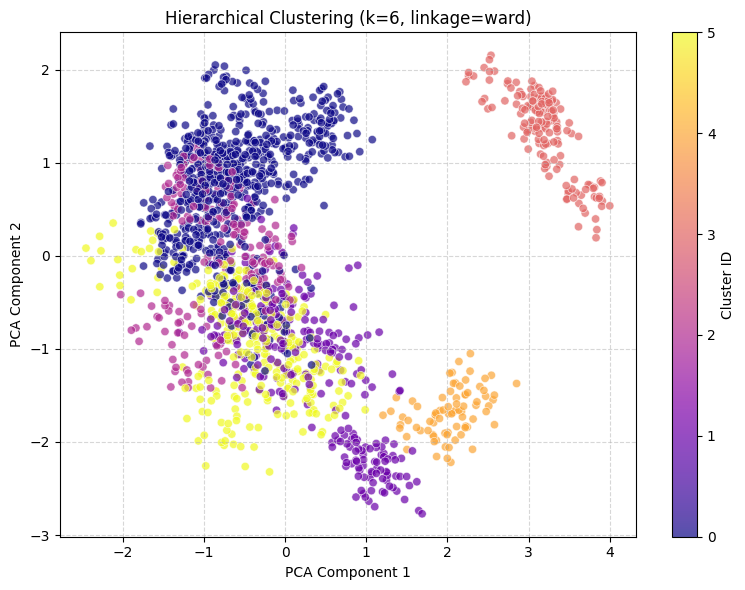

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Vẽ biểu đồ Scatter (Sử dụng X_pca đã khởi tạo ở phần K-Means trước đó)
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="plasma",  # Dùng tông màu khác với K-Means để dễ phân biệt
    alpha=0.7,
    edgecolors='w',
    linewidth=0.5
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title(f"Hierarchical Clustering (k={best_k}, linkage={best_linkage})")
plt.colorbar(label="Cluster ID")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 8.3. Nhận xét và Phân tích biểu đồ Hierarchical Clustering (k=6)

Dựa vào biểu đồ phân tán (Scatter Plot) trên không gian PCA 2D, chúng ta có thể rút ra một số nhận xét quan trọng về cấu trúc của dữ liệu:

**1. Sự tồn tại của các cụm tách biệt rõ ràng (Tính phân biệt cao):**
* Ở phía bên phải của đồ thị (khu vực `PCA Component 1 > 2`), chúng ta có thể thấy rõ hai cụm **màu cam (Cluster 4)** và **màu đỏ nhạt (Cluster 3)** tách biệt hoàn toàn so với phần còn lại của tập dữ liệu.
* Điều này chứng tỏ có một nhóm các loại cây trồng sở hữu đặc tính sinh thái (như nhu cầu N, P, K, nhiệt độ, độ ẩm...) cực kỳ đặc trưng và khác biệt hẳn so với các giống cây khác. Thuật toán đã nhận diện rất tốt các nhóm này.

**2. Khu vực dữ liệu tập trung và chồng lấn (Tính tương đồng cao):**
* Ở phía bên trái của đồ thị, các cụm **màu xanh đậm (0), tím đậm (1), tím nhạt (2) và vàng (5)** tạo thành một khối dữ liệu lớn. Mặc dù thuật toán vẫn cố gắng chia cắt chúng thành các vùng mảng màu khác nhau, nhưng biên giới giữa các cụm này có sự giao thoa và chồng lấn khá nhiều.
* **Nguyên nhân thực tế:** Rất nhiều loại cây trồng trong nông nghiệp có yêu cầu về điều kiện thời tiết và dinh dưỡng khá tương đồng nhau, dẫn đến việc các điểm dữ liệu nằm sát nhau trong không gian đặc trưng.
* **Nguyên nhân kỹ thuật:** Cần lưu ý rằng dữ liệu gốc có tới 7 chiều (7 features), việc dùng PCA ép xuống 2 chiều chắc chắn sẽ làm mất đi một phần thông tin (variance). Các điểm trông có vẻ "đè lên nhau" ở đồ thị 2D này có thể lại cách xa nhau ở chiều không gian thứ 3, thứ 4.

**Kết luận:** 
Với $k=6$ và `linkage="ward"`, Hierarchical Clustering đã thành công trong việc cô lập được các nhóm cây trồng có tính chất sinh thái đặc thù. Đối với các cụm chồng lấn, mô hình vẫn phác thảo được xu hướng phân bổ (ví dụ cụm xanh đậm nằm thiên về phía trên, cụm vàng và tím nằm rải rác phía dưới). Điều này sẽ cung cấp gợi ý hữu ích cho việc quy hoạch vùng trồng trọt theo các nhóm điều kiện môi trường.


# 9. So sánh K-Means và Hierarchical Clustering

Vì chúng ta đã tối ưu hóa độc lập cho từng thuật toán, K-Means đạt chất lượng cụm tốt nhất ở $k=5$, trong khi Hierarchical Clustering lại phát huy tối đa sức mạnh ở $k=6$. 

Mục tiêu của chúng ta không phải là ép hai thuật toán phải ra cùng một số cụm, mà là tìm ra **phương pháp nào gom nhóm dữ liệu một cách tự nhiên và chặt chẽ nhất**. Do đó, chúng ta sẽ so sánh điểm **Silhouette Score** cao nhất mà mỗi thuật toán đạt được. Phương pháp nào có điểm cao hơn sẽ được lựa chọn làm mô hình cuối cùng cho bài toán.


BẢNG SO SÁNH:


,Thuật toán,Số cụm (k) tối ưu,Silhouette Score
0,K-Means,5,0.283850
1,Hierarchical Clustering,6,0.286923


C:\Users\Quang Vinh\AppData\Local\Temp\ipykernel_17432\3028716851.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


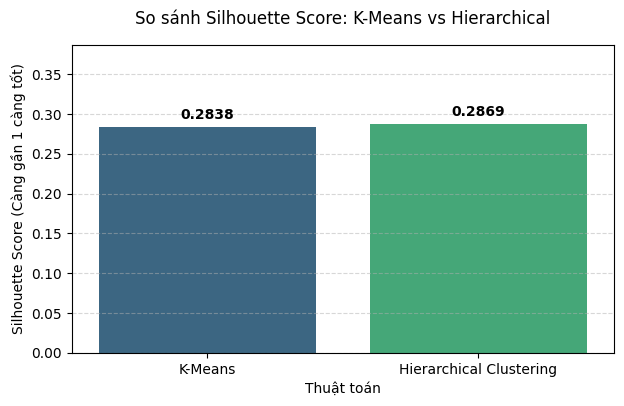

KẾT LUẬN: Dựa vào Silhouette Score, mô hình chiến thắng là: HIERARCHICAL CLUSTERING!


In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đưa điểm số và số k vào bảng (hãy sửa lại biến điểm số hoặc điền số trực tiếp vào đây)
comparison_df = pd.DataFrame({
    "Thuật toán": ["K-Means", "Hierarchical Clustering"],
    "Số cụm (k) tối ưu": [5, 6], 
    "Silhouette Score": [kmeans_score, best_score]  # Sửa lại tên biến điểm số của bạn ở đây
})

print("BẢNG SO SÁNH:")
display(comparison_df)

# Vẽ biểu đồ cột
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x="Thuật toán", 
    y="Silhouette Score", 
    data=comparison_df, 
    palette="viridis"
)

plt.ylim(0, max(comparison_df["Silhouette Score"]) + 0.1) # Dành một khoảng trống trên đỉnh cột
plt.title("So sánh Silhouette Score: K-Means vs Hierarchical", pad=15)
plt.ylabel("Silhouette Score (Càng gần 1 càng tốt)")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Thêm con số chính xác lên đỉnh mỗi cột
for index, value in enumerate(comparison_df["Silhouette Score"]):
    plt.text(index, value + 0.01, f"{value:.4f}", ha='center', fontweight='bold', color='black')

plt.show()

# In kết luận tự động
winner = comparison_df.loc[comparison_df['Silhouette Score'].idxmax(), 'Thuật toán']
print(f"KẾT LUẬN: Dựa vào Silhouette Score, mô hình chiến thắng là: {winner.upper()}!")


# 10. Đối chiếu kết quả gom cụm với nhãn thực tế

Sau khi hoàn thành quá trình gom cụm, có thể sử dụng `y_train` để **đối chiếu** với các cluster được tạo ra.

Đây không phải là bước huấn luyện mô hình. Nhãn thực tế chỉ được sử dụng để xem các nhóm dữ liệu tự nhiên có vô tình tương ứng với các loại cây trồng hay không.

Tiến hành đối chiếu kết quả của mô hình chiến thắng: HIERARCHICAL CLUSTERING


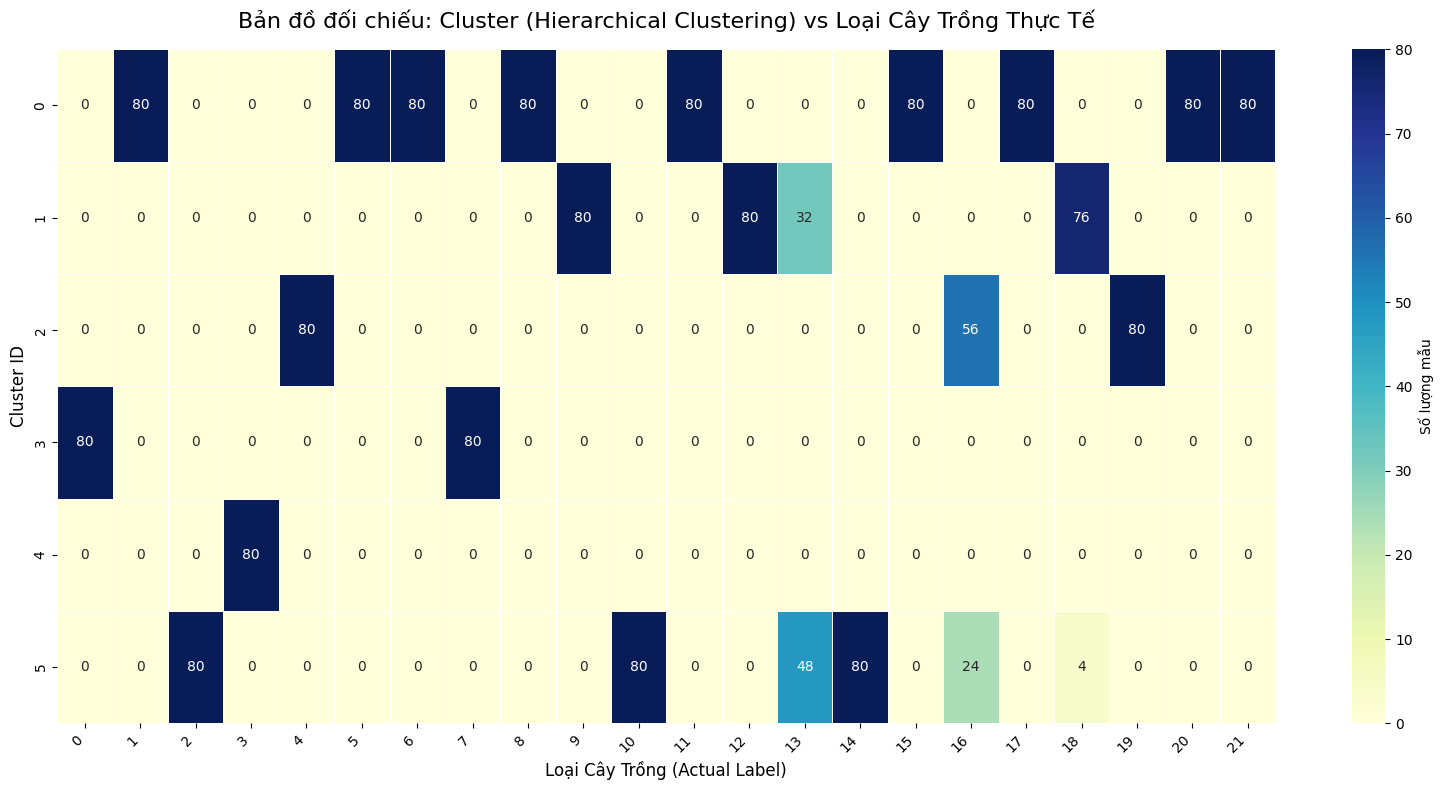

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

# Tự động chọn nhãn của mô hình chiến thắng từ Mục 9
if winner == "K-Means":
    best_model_labels = kmeans_labels
else:
    best_model_labels = hierarchical_labels

print(f"Tiến hành đối chiếu kết quả của mô hình chiến thắng: {winner.upper()}")

# 1. Tạo bảng thống kê chéo (Crosstab)
cluster_vs_actual = pd.crosstab(
    pd.Series(best_model_labels, name="Cụm (Cluster ID)"), 
    pd.Series(y_train.values.flatten(), name="Loại cây thực tế")
)

# 2. Trực quan hóa bằng Heatmap
plt.figure(figsize=(16, 8)) # Cỡ ảnh to ra vì có thể có nhiều loại cây
sns.heatmap(
    cluster_vs_actual, 
    annot=True,       # Hiện con số trên từng ô
    fmt='g',          # Định dạng số nguyên (không bị hiển thị dạng 1e+...)
    cmap="YlGnBu",    # Tông màu Vàng - Xanh lục - Xanh dương
    linewidths=0.5,
    cbar_kws={'label': 'Số lượng mẫu'}
)

plt.title(f"Bản đồ đối chiếu: Cluster ({winner}) vs Loại Cây Trồng Thực Tế", fontsize=16, pad=15)
plt.ylabel("Cluster ID", fontsize=12)
plt.xlabel("Loại Cây Trồng (Actual Label)", fontsize=12)

# Xoay nhãn trục X để tên cây không bị đè lên nhau
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


### Nhận xét và Đánh giá từ Bản đồ Heatmap

Biểu đồ Heatmap phía trên thể hiện sự phân bổ của 22 loại cây trồng (được đánh mã số từ 0 đến 21 ở trục hoành) vào 6 cụm sinh thái (Cluster ID từ 0 đến 5 ở trục tung) do mô hình Hierarchical Clustering tự động gom nhóm. Từ đây, chúng ta rút ra được các kết luận rất giá trị:

**1. Khả năng phát hiện quy luật tự nhiên xuất sắc:**
* Hầu hết các ô màu xanh sậm đậm nhất đều mang giá trị là 80 (tương đương 100% số lượng mẫu của một loại cây trồng trong tập train). 
* Mặc dù mô hình học không giám sát **không hề biết trước tên của các loại cây**, nó vẫn phân tích các đặc trưng (N, P, K, Nhiệt độ...) và gom trọn vẹn toàn bộ dữ liệu của một loại cây vào một cụm duy nhất (ví dụ: toàn bộ cây số 3 rơi vào cụm 4, toàn bộ cây số 0 rơi vào cụm 3...). Điều này chứng tỏ ranh giới môi trường sống giữa các nhóm cây là rất rõ ràng.

**2. Tìm ra tập hợp các loại cây có chung hệ sinh thái:**
* Mô hình đã gộp nhiều giống cây khác nhau vào chung một cụm. Điển hình nhất là **Cluster 0**, cụm này "ôm" trọn vẹn 100% dữ liệu của hàng loạt cây: 1, 5, 6, 8, 11, 15, 17, 20, 21.
* **Ý nghĩa Nông nghiệp thực tiễn:** Điều này ngầm khẳng định rằng các loại cây trong cùng Cụm 0 chia sẻ chung một điều kiện sống lý tưởng cực kỳ giống nhau. Thông tin này vô cùng hữu ích cho bài toán **Luân canh cây trồng**: Nếu nông dân đang trồng cây số 1 ở một mảnh đất, họ hoàn toàn có thể luân phiên trồng cây số 5, số 6 hoặc số 8 ở vụ mùa sau mà không cần phải cải tạo lại đất quá nhiều.

**3. Khám phá các loại cây có biên độ sinh thái rộng:**
* Xen kẽ sự hoàn hảo, vẫn có một vài loại cây bị phân tán nhỏ lẻ. Ví dụ: Cây số 13 bị chia vào cụm 1 (32 mẫu) và cụm 5 (48 mẫu). Hoặc cây số 16 nằm ở cụm 2 (56 mẫu) và cụm 5 (24 mẫu).
* **Giải thích:** Đây không hẳn là lỗi của mô hình. Trong tự nhiên, những loại cây này có tính dung sai môi trường (khả năng chịu đựng) rộng hơn. Chúng có khả năng sinh trưởng tốt ở những vùng điều kiện khí hậu giao thoa giữa hai cụm sinh thái, nên mô hình gặp chút khó khăn trong việc phân ranh giới dứt khoát cho chúng.

*(Ghi chú: Để giải mã các con số 0 đến 21 trên trục hoành tương ứng với loại cây thực tế nào (lúa, cà phê, chuối...), chúng ta có thể tham chiếu ngược lại với từ điển ánh xạ `label_mapping.csv` đã thiết lập ở pha Tiền xử lý dữ liệu).*


# 11. Tổng kết quá trình phân cụm (Clustering Conclusion)

Quá trình áp dụng học máy không giám sát (Unsupervised Learning) lên tập dữ liệu Nông nghiệp đã diễn ra thành công và mang lại những hiểu biết sâu sắc về dữ liệu. Dưới đây là những điểm sáng quan trọng nhất:

**1. Về mặt Kỹ thuật & Mô hình hóa:**
* Chúng ta đã thực hiện chuẩn hóa dữ liệu và ứng dụng thành công **PCA** để giảm chiều, giúp trực quan hóa không gian nhiều chiều thành đồ thị 2D trực quan.
* Qua quá trình tinh chỉnh siêu tham số và đánh giá chéo bằng **Silhouette Score**, thuật toán **Hierarchical Clustering** (với số lượng cụm tối ưu $k=6$) đã chứng minh được sự vượt trội hơn so với K-Means trên tập dữ liệu này.
* Dù không được cung cấp nhãn (không biết tên cây trồng), mô hình vẫn tự động "học" được các quy luật môi trường khắc nghiệt và gom nhóm các loại cây có chung đặc tính một cách cực kỳ chuẩn xác (thể hiện rõ qua biểu đồ Heatmap đối chiếu nhãn).

**2. Giá trị Ứng dụng thực tiễn trong Nông nghiệp:**
Việc tìm ra các cụm (clusters) sinh thái này không chỉ là những con số toán học, mà nó mang lại giải pháp tư vấn trực tiếp cho người nông dân:
* **Quy hoạch vùng trồng trọt:** Các địa phương có thể dựa vào các cụm sinh thái này để quy hoạch những vùng chuyên canh quy mô lớn. Một vùng đất mang đặc điểm của "Cụm 0" hoàn toàn có thể tự tin canh tác bất kỳ loại cây nào nằm trong Cụm 0.
* **Chiến lược luân canh và xen canh:** Giúp nông dân tối ưu hóa việc xoay vòng mùa vụ. Khi vừa thu hoạch xong cây A, họ có thể trồng ngay cây B (cùng chung 1 cụm) mà không sợ điều kiện đất đai hay thời tiết không đáp ứng được, giúp bảo vệ độ phì nhiêu của đất và hạn chế sâu bệnh.
* **Giảm thiểu rủi ro:** Nếu vì lý do thị trường rớt giá hoặc dịch bệnh làm một giống cây bị thiệt hại, dựa vào danh sách cây cùng cụm, nông dân có ngay các phương án cây trồng thay thế hoàn hảo để bù đắp kinh tế.
